In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import ArmaProcess
from scipy.optimize import newton
from scipy.optimize import linprog

rng = np.random.default_rng(1)

λ̂ = 0.25


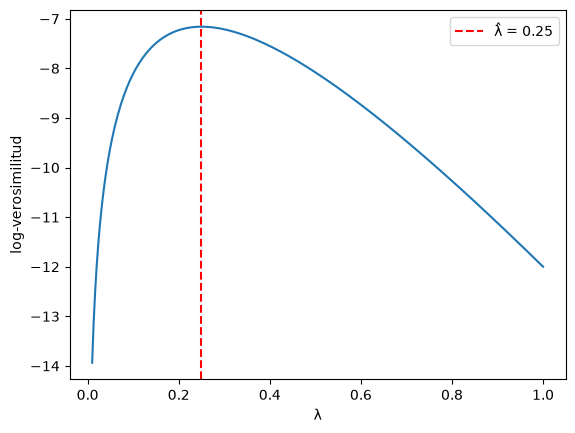

5 0.1726827448085243
50 0.22397471865045088
500 0.26086241186474
5000 0.25110817601602425
media: 5.0302  varianza: 5.055087959999999  λt: 5.0
P(N=0) simulada: 0.007  teórica: 0.006737946999085467


In [ ]:
#Coger una muestra aleatoria; x \sim \exp(\lambda) de n v.a.

#x \sim \exp(\lambda) (definición) ->  Poisson
# \lambda como se interpreta?
# \lambda gorro M.V.


# --- A) Log-verosimilitud del ejemplo del bus ---
datos = np.array([2, 4, 6])
n = len(datos)

def loglik(lam):
    return n*np.log(lam) - lam*datos.sum()

lambdas = np.linspace(0.01, 1, 300)
lam_hat = n / datos.sum()                      # 1/media
print("λ̂ =", lam_hat)

plt.plot(lambdas, loglik(lambdas))
plt.axvline(lam_hat, color="red", linestyle="--", label=f"λ̂ = {lam_hat:.2f}")
plt.xlabel("λ"); plt.ylabel("log-verosimilitud"); plt.legend()
plt.show()

# --- B) Consistencia: λ̂ se acerca a λ al crecer n ---
lam_real = 0.25
for m in [5, 50, 500, 5000]:
    x = rng.exponential(scale=1/lam_real, size=m)   # scale = 1/λ
    print(m, 1/x.mean())

# --- C) Relación con Poisson ---
lam, t = 0.25, 20
conteos = []
for _ in range(10000):
    tiempo, k = 0, 0
    while True:
        tiempo += rng.exponential(1/lam)
        if tiempo > t:
            break
        k += 1
    conteos.append(k)
conteos = np.array(conteos)

print("media:", conteos.mean(), " varianza:", conteos.var(), " λt:", lam*t)
print("P(N=0) simulada:", (conteos==0).mean(), " teórica:", np.exp(-lam*t))

f(0) = 0.35  f(1) = 0.65


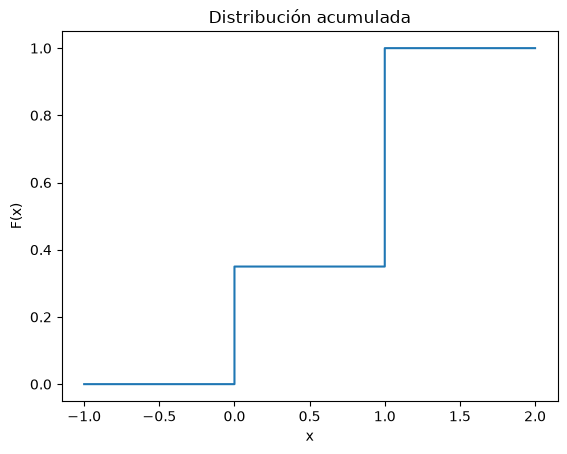

10 proporción de sellos: 0.7
100 proporción de sellos: 0.62
10000 proporción de sellos: 0.6469


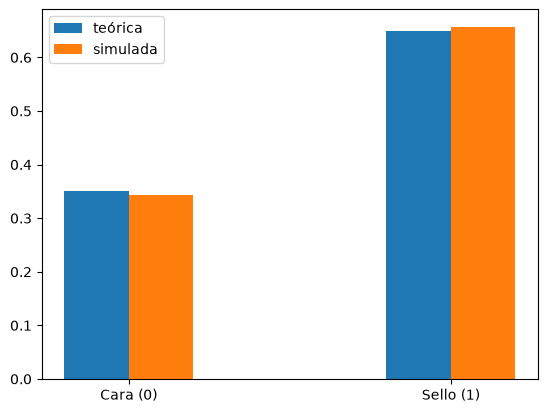

In [ ]:
#Tarea: Experimento aleatorio de lanzar una moneda. Espacio muestral: S = {cara, sello}.
#V.A. asociada (será discreta). p = 0.65 (sello); p = 0.35 (cara).
#F.D. función de distribución acumulada.
#f.d. función de masa de probabilidad.

p = 0.65
rng = np.random.default_rng(1)

# --- A) Masa de probabilidad teórica ---
valores = [0, 1]
masa = [1-p, p]
print("f(0) =", masa[0], " f(1) =", masa[1])

# --- B) Función de distribución acumulada (escalera) ---
def F(x):
    x = np.asarray(x, dtype=float)
    return np.where(x < 0, 0.0, np.where(x < 1, 1-p, 1.0))

xs = np.linspace(-1, 2, 1000)
plt.step(xs, F(xs), where="post")
plt.xlabel("x"); plt.ylabel("F(x)"); plt.title("Distribución acumulada")
plt.show()

# --- C) Simulación: lanzar la moneda muchas veces ---
for n in [10, 100, 10000]:
    lanzamientos = rng.random(n) < p         # True = sello
    print(n, "proporción de sellos:", lanzamientos.mean())

# --- D) Masa empírica vs teórica con 10000 lanzamientos ---
x = (rng.random(10000) < p).astype(int)
emp = [np.mean(x == 0), np.mean(x == 1)]
plt.bar([-0.1, 0.9], masa, width=0.2, label="teórica")
plt.bar([0.1, 1.1], emp, width=0.2, label="simulada")
plt.xticks([0, 1], ["Cara (0)", "Sello (1)"]); plt.legend()
plt.show()

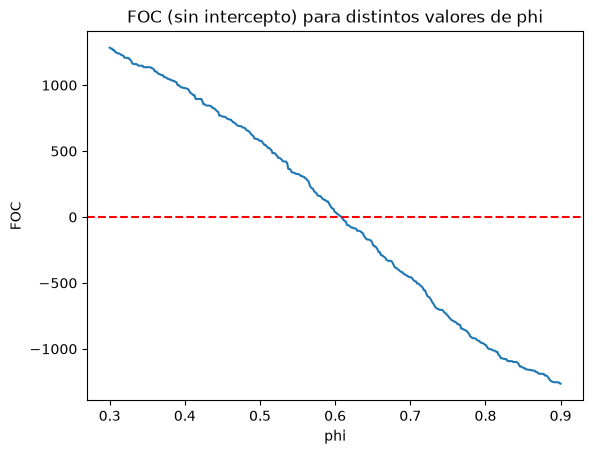

Verdadero             : phi = 0.6, b = 1.0  (caso B: c = 1.0)
--- Caso A: SIN intercepto ---
MCO                   : phi = 0.6127
LAD (mediana pond.)   : phi = 0.6083   b_hat = 0.9855
--- Caso B: CON intercepto ---
MCO                   : c = 1.0594, phi = 0.5812
LAD (prog. lineal)    : c = 1.0110, phi = 0.6004   b_hat = 0.9942
LAD (IRLS)            : c = 1.0110, phi = 0.6004
Mediana de residuos LAD (FOC en c, debe ser ~0): -0.0000
Residuos exactamente 0 en la solución LP (al menos 2): 2


In [ ]:
#Plantear las ecuaciones de primer orden de la estimación por MV para un AR(1), con intercepto y sin intercepto, con ruido blanco Laplace en lugar de normal.
#Verificar cómo difieren las soluciones con intercepto frente a sin intercepto, y cuál tiene solución cerrada y cuál no.
#Investigar qué método de solución se puede aplicar a ese sistema de ecuaciones, en los dos casos (con y sin intercepto), cuando los errores son Laplace.
#Investigar en qué se diferencia la distribución Laplace de la Normal.
#Investigar qué aplicaciones tiene la distribución Laplace.
#Investigar qué es una regresión LAD.
#Investigar cómo se conecta la regresión LAD con un AR(1) con ruido blanco Laplace.

# 1. Simular un AR(1) con ruido Laplace: y_t = c + phi*y_{t-1} + e_t
np.random.seed(16)
T, phi_verdadero, b_verdadero = 2000, 0.6, 1.0


def simular(c):
    e = np.random.laplace(loc=0, scale=b_verdadero, size=T + 200)
    y = np.zeros(T + 200)
    for t in range(1, T + 200):
        y[t] = c + phi_verdadero * y[t - 1] + e[t]
    y = y[200:]                          # se descartan los primeros 200 datos (burn-in)
    return y[1:], y[:-1]                 # y_t  y  y_{t-1}


# Caso A: sin intercepto (c = 0)      Caso B: con intercepto (c = 1)
yA_t, yA_l = simular(c=0.0)
c_verdadero = 1.0
yB_t, yB_l = simular(c=c_verdadero)


# 2. FOC con signos (reemplaza a las FOC lineales del caso normal)
def FOC_sin_intercepto(phi):
    e = yA_t - phi * yA_l
    return np.sum(np.sign(e) * yA_l)                    # sum sgn(e_t) * y_{t-1}


def FOC_con_intercepto(c, phi):
    e = yB_t - c - phi * yB_l
    return np.sum(np.sign(e)), np.sum(np.sign(e) * yB_l)   # (FOC en c, FOC en phi)


# 3. Visualizar la FOC sin intercepto: es una escalera, no una curva suave
x = np.linspace(0.3, 0.9, 400)
plt.plot(x, [FOC_sin_intercepto(p) for p in x])
plt.axhline(0, linestyle="--", color="red")
plt.title("FOC (sin intercepto) para distintos valores de phi")
plt.xlabel("phi")
plt.ylabel("FOC")
plt.show()


# 4. Caso A (sin intercepto): mediana ponderada de y_t / y_{t-1}
def mediana_ponderada(valores, pesos):
    orden = np.argsort(valores)
    v, w = valores[orden], pesos[orden]
    acumulado = np.cumsum(w)
    return v[np.searchsorted(acumulado, 0.5 * acumulado[-1])]


phi_lad_A = mediana_ponderada(yA_t / yA_l, np.abs(yA_l))
phi_mco_A = (yA_t @ yA_l) / (yA_l @ yA_l)

# 5. Caso B (con intercepto): programación lineal
#    min sum(u + v)   s.a.   c + phi*y_{t-1} + u - v = y_t,   u, v >= 0
n = len(yB_t)
X = np.column_stack([np.ones(n), yB_l])
costo = np.concatenate([[0, 0], np.ones(2 * n)])
A_eq = np.hstack([X, np.eye(n), -np.eye(n)])
limites = [(None, None)] * 2 + [(0, None)] * (2 * n)
sol = linprog(costo, A_eq=A_eq, b_eq=yB_t, bounds=limites, method="highs")
c_lad, phi_lad_B = sol.x[:2]

# 6. Caso B con IRLS (mínimos cuadrados reponderados)
c_mco, phi_mco_B = np.linalg.lstsq(X, yB_t, rcond=None)[0]   # MCO (caso normal)
beta = np.array([c_mco, phi_mco_B])                          # IRLS arranca en MCO
for _ in range(200):
    resid = yB_t - X @ beta
    w = 1 / np.maximum(np.abs(resid), 1e-6)                  # pesos 1/|e_t|
    beta_nuevo = np.linalg.solve(X.T @ (w[:, None] * X), X.T @ (w * yB_t))
    if np.linalg.norm(beta_nuevo - beta) < 1e-10:
        beta = beta_nuevo
        break
    beta = beta_nuevo

# 7. b_hat = error absoluto medio de los residuos (caso A y caso B)
b_hat_A = np.mean(np.abs(yA_t - phi_lad_A * yA_l))
resid_B = yB_t - c_lad - phi_lad_B * yB_l
b_hat_B = np.mean(np.abs(resid_B))

print(f"Verdadero             : phi = {phi_verdadero}, b = {b_verdadero}  (caso B: c = {c_verdadero})")
print("--- Caso A: SIN intercepto ---")
print(f"MCO                   : phi = {phi_mco_A:.4f}")
print(f"LAD (mediana pond.)   : phi = {phi_lad_A:.4f}   b_hat = {b_hat_A:.4f}")
print("--- Caso B: CON intercepto ---")
print(f"MCO                   : c = {c_mco:.4f}, phi = {phi_mco_B:.4f}")
print(f"LAD (prog. lineal)    : c = {c_lad:.4f}, phi = {phi_lad_B:.4f}   b_hat = {b_hat_B:.4f}")
print(f"LAD (IRLS)            : c = {beta[0]:.4f}, phi = {beta[1]:.4f}")
print(f"Mediana de residuos LAD (FOC en c, debe ser ~0): {np.median(resid_B):.4f}")
print(f"Residuos exactamente 0 en la solución LP (al menos 2): {np.sum(np.abs(resid_B) < 1e-8)}")

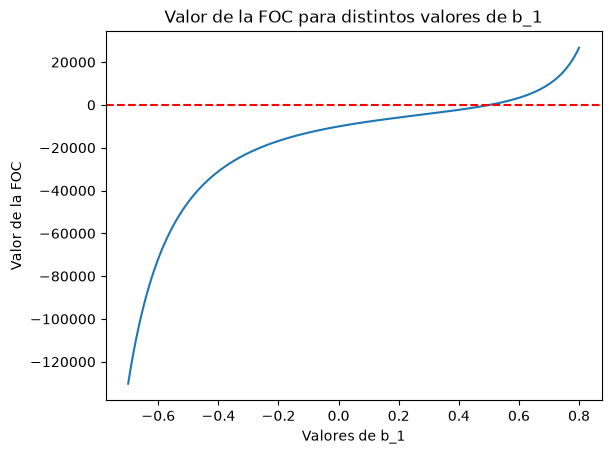

0.7643741709791686
0.666538769022849
0.5669914987173036
0.5113065124272879
0.5020692220652281
0.5018900521948556
0.5018899894196621
b_1 estimado (a mano): 0.5018899894196621
b_1 estimado (scipy) : 0.5018899894199674
b_1 verdadero        : 0.5


In [ ]:
# Resuelva Numéricamente las ecuaciones de primer 
# orden que se obtienen al aplicar MV para un MA(1) 
# con ruido blanco normal y resolverlas 
# numéricamente con el método de Netwo-Rhapson

# 1. Simular un MA(1): y_t = e_t + 0.5 e_{t-1}
np.random.seed(16)
yt_ma1 = ArmaProcess(ar=[1], ma=[1, 0.5]).generate_sample(nsample=20000)


# 2. Los tres vectores (con e_0 = 0)
def vectores(y_t, b_1):
    """Devuelve: residuos e_t, primeras derivadas de e_t y segundas derivadas de e_t (respecto a b_1)."""
    T = len(y_t)
    e = np.zeros(T)    # e_t        = y_t - b_1 * e_{t-1}
    d1 = np.zeros(T)   # de_t/db    = -e_{t-1} - b_1 * de_{t-1}/db
    d2 = np.zeros(T)   # d2e_t/db2  = -2 * de_{t-1}/db - b_1 * d2e_{t-1}/db2

    for t in range(1, T):   # en t = 0 los tres valen: e_0 = 0, y las derivadas son 0
        e[t] = y_t[t] - b_1 * e[t - 1]
    e[0] = y_t[0]           # e_1 = y_1 - b_1 * e_0 = y_1

    for t in range(1, T):
        d1[t] = -e[t - 1] - b_1 * d1[t - 1]
        d2[t] = -2 * d1[t - 1] - b_1 * d2[t - 1]

    return e, d1, d2


# 3. FOC y SOC
def FOC(y_t, b_1):
    e, d1, _ = vectores(y_t, b_1)
    return np.sum(e * d1)                  # multiplicar entrada por entrada y sumar


def SOC(y_t, b_1):
    e, d1, d2 = vectores(y_t, b_1)
    return np.sum(d1 ** 2 + e * d2)


# 4. Visualizar la CPO: ¿dónde corta el cero?
x = np.linspace(-0.7, 0.8, 200)
plt.plot(x, [FOC(yt_ma1, b) for b in x])
plt.axhline(0, linestyle="--", color="red")
plt.title("Valor de la FOC para distintos valores de b_1")
plt.xlabel("Valores de b_1")
plt.ylabel("Valor de la FOC")
plt.show()


# 5. Newton-Raphson: b^(1) = b^(0) - CPO / CSO
def newton_raphson(b_inicial, tol=0.00005):
    b_inicio = b_inicial
    while True:
        b_final = b_inicio - FOC(yt_ma1, b_inicio) / SOC(yt_ma1, b_inicio)
        print(b_final)
        if abs(b_final - b_inicio) < tol:
            return b_final
        b_inicio = b_final


b_hat = newton_raphson(0.84)
print("b_1 estimado (a mano):", b_hat)

# 6. Verificación con scipy
raiz = newton(lambda b: FOC(yt_ma1, b), x0=0.1, fprime=lambda b: SOC(yt_ma1, b))
print("b_1 estimado (scipy) :", raiz)
print("b_1 verdadero        : 0.5")